In [191]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [192]:
df = pd.read_csv("csv/heart.csv")
df.head()

,age,sex,cp,trtbps,chol,fbs,restecg,thalachh,exng,oldpeak,slp,caa,thall,output
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [193]:
x = df.drop(columns=['output','oldpeak','slp','thall'])
y = df['output']
x = np.asarray(x)
y = np.asarray(y)

In [194]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=4)

In [195]:
from sklearn import svm
from sklearn.metrics import jaccard_score, f1_score, accuracy_score
for kernel in ['rbf','poly','linear','sigmoid']:
    try:
        clf = svm.SVC(kernel=kernel).fit(x_train, y_train)
        y_pre_svm = clf.predict(x_test)
        ja = jaccard_score(y_test, y_pre_svm, pos_label=0)
        f1 = f1_score(y_test, y_pre_svm, average='weighted')
        acc = accuracy_score(y_test, y_pre_svm)
        print("kernel: ",kernel,"\njaccard score: ",ja,"\nf1 score: ",f1,"\naccuracy score: ",acc,"\n")
    except Exception as e:
        print("Error: ",e)

kernel:  rbf 
jaccard score:  0.3225806451612903 
f1 score:  0.6370785019325603 
accuracy score:  0.6557377049180327 

kernel:  poly 
jaccard score:  0.3870967741935484 
f1 score:  0.6769714839998648 
accuracy score:  0.6885245901639344 

kernel:  linear 
jaccard score:  0.7777777777777778 
f1 score:  0.9009193619849357 
accuracy score:  0.9016393442622951 

kernel:  sigmoid 
jaccard score:  0.0 
f1 score:  0.4380598276153456 
accuracy score:  0.5901639344262295 



In [196]:
clf = svm.SVC(kernel='linear').fit(x_train, y_train)
y_pre_svm = clf.predict(x_test)

In [197]:
from sklearn.metrics import classification_report, confusion_matrix
import itertools

def plot_confusion_matrix(cm, classes,
                          normalize=False,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues):
    """
    This function prints and plots the confusion matrix.
    Normalization can be applied by setting `normalize=True`.
    """
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        print("Normalized confusion matrix")
    else:
        print('Confusion matrix, without normalization')

    print(cm)

    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    fmt = '.2f' if normalize else 'd'
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], fmt),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

              precision    recall  f1-score   support

           0       0.91      0.84      0.88        25
           1       0.89      0.94      0.92        36

    accuracy                           0.90        61
   macro avg       0.90      0.89      0.90        61
weighted avg       0.90      0.90      0.90        61

Confusion matrix, without normalization
[[21  4]
 [ 2 34]]


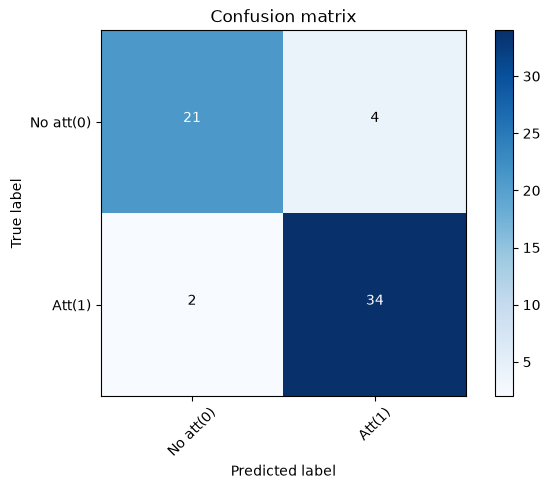

In [198]:
cnf_matrix = confusion_matrix(y_test, y_pre_svm, labels=[0,1])
np.set_printoptions(precision=2)

print (classification_report(y_test, y_pre_svm))

# Plot non-normalized confusion matrix
plt.figure()
plot_confusion_matrix(cnf_matrix, classes=['No att(0)','Att(1)'],normalize= False,  title='Confusion matrix')

In [199]:
from sklearn.tree import DecisionTreeClassifier
for criterion in ['entropy','gini','log_loss']:
    try:
        att_tree = DecisionTreeClassifier(criterion=criterion, max_depth = 4).fit(x_train, y_train)
        y_pre_tree = att_tree.predict(x_test)
        ja = jaccard_score(y_test, y_pre_tree, pos_label=0)
        f1 = f1_score(y_test, y_pre_tree, average='weighted')
        acc = accuracy_score(y_test, y_pre_tree)
        print("criterion: ",criterion,"\njaccard score: ",ja,"\nf1 score: ",f1,"\naccuracy score: ",acc,"\n")
    except Exception as e:
        print("Error: ",e)

criterion:  entropy 
jaccard score:  0.6666666666666666 
f1 score:  0.8211402006361633 
accuracy score:  0.819672131147541 

criterion:  gini 
jaccard score:  0.7 
f1 score:  0.8528664756135655 
accuracy score:  0.8524590163934426 

criterion:  log_loss 
jaccard score:  0.6666666666666666 
f1 score:  0.8211402006361633 
accuracy score:  0.819672131147541 



In [200]:
att_tree = DecisionTreeClassifier(criterion='gini', max_depth = 4).fit(x_train, y_train)
y_pre_tree = att_tree.predict(x_test)

In [201]:
def plot_confusion_matrix(cm, classes,
                          normalize=False,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues):
    """
    This function prints and plots the confusion matrix.
    Normalization can be applied by setting `normalize=True`.
    """
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        print("Normalized confusion matrix")
    else:
        print('Confusion matrix, without normalization')

    print(cm)

    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    fmt = '.2f' if normalize else 'd'
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], fmt),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

              precision    recall  f1-score   support

           0       0.81      0.84      0.82        25
           1       0.89      0.86      0.87        36

    accuracy                           0.85        61
   macro avg       0.85      0.85      0.85        61
weighted avg       0.85      0.85      0.85        61

Confusion matrix, without normalization
[[21  4]
 [ 5 31]]


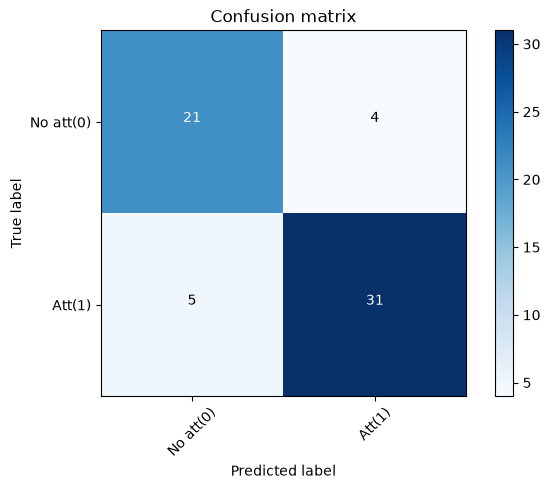

In [202]:
cnf_matrix = confusion_matrix(y_test, y_pre_tree, labels=[0,1])
np.set_printoptions(precision=2)

print (classification_report(y_test, y_pre_tree))

# Plot non-normalized confusion matrix
plt.figure()
plot_confusion_matrix(cnf_matrix, classes=['No att(0)','Att(1)'],normalize= False,  title='Confusion matrix')